<!-- Main Title -->
<h1 style="color: #FECB05; text-align: center;">Agrupamiento (Clustering)</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- Introducción al clustering
- K-Medias: pseudo-algoritmo, implementación y método del codo
- Ejemplo 1: Iris
- Evaluación de los grupos, escalado e inicialización
- Ejemplo 2: dígitos manuscritos
- Referencias

---

<!-- Section 1 -->
<h2 id="section1" style="color: #007ACC;">Introducción</h2>

El clustering en Machine Learning es una técnica fundamental que se utiliza para identificar estructuras subyacentes dentro de conjuntos de datos no etiquetados. A diferencia del aprendizaje supervisado, donde se tienen etiquetas predefinidas para entrenar un modelo, el clustering busca agrupar datos similares en clusters o grupos, sin necesidad de etiquetas previas. Este enfoque es ampliamente utilizado en diversas aplicaciones, como segmentación de clientes, análisis de redes sociales, clasificación de documentos y reconocimiento de patrones en imágenes, entre otros. En esencia, el clustering busca descubrir la estructura oculta dentro de los datos, lo que puede proporcionar insights valiosos para la toma de decisiones y la comprensión de fenómenos complejos.

<img src='../img/clustering.jpeg'>

<!-- Section 1 -->
<h2 id="section1" style="color: #007ACC;">K-Medias</h2>

El algoritmo K-Medias es uno de los métodos de clustering más populares en Machine Learning. Su objetivo principal es dividir un conjunto de datos en K grupos distintos, donde cada punto de datos pertenece al grupo cuyo centroide (o centro de masa) está más cercano. La idea central del algoritmo es asignar iterativamente puntos de datos a los clusters más cercanos y luego actualizar los centroides de los clusters en función de los puntos asignados. Este proceso se repite hasta que se alcanza la convergencia, es decir, cuando los centroides de los clusters ya no cambian significativamente entre iteraciones. K-Medias es eficiente y fácil de implementar, pero su rendimiento puede depender fuertemente de la elección inicial de los centroides y la métrica de distancia utilizada. A pesar de sus limitaciones, K-Medias sigue siendo ampliamente utilizado en aplicaciones de clustering debido a su simplicidad y escalabilidad.

<h3 id="subsection1-1" style="color: #003366;">Pseudo-algoritmo</h3>

1. Escogemos el número de grupos (clústers), $K$, e inicializamos los $K$ centroides (de forma aleatoria o con una estrategia como *k-means++*).

2. Asignamos cada punto $i$ al grupo $k$ cuyo centroide es el más cercano.

3. Actualizamos cada centroide como la media de los puntos asignados a su grupo.

4. Repetimos 2 y 3 hasta que las asignaciones dejen de cambiar (o la inercia deje de disminuir), es decir, hasta que haya convergencia a un mínimo local.

Al terminar, la inercia de la agrupación (suma de las distancias al cuadrado de cada punto a su centroide) es:

$$J(K) =  \sum_{k = 1}^{K} \sum_{i \in C_{k}} \vert \vert x_{i} - \mu_{k} \vert \vert  ^{2} $$

donde $C_{k}$ es el conjunto de puntos asignados al grupo $k$ y $\mu_{k}$ su centroide. Como el algoritmo solo garantiza un mínimo *local* de $J$, el resultado depende de la inicialización; por eso se ejecuta varias veces con distintas semillas (`n_init`) y se conserva la mejor solución.

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.


In [ ]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn scipy scikit-learn


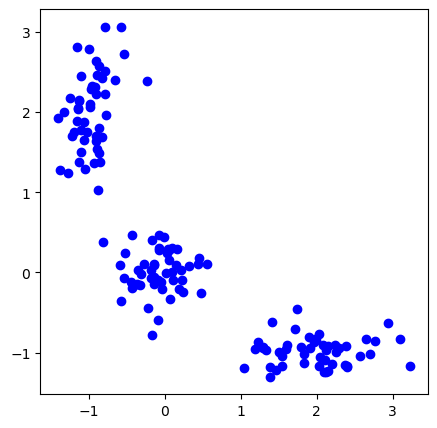

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Let's begin by allocation 3 cluster's points
X = np.zeros((150, 2))

np.random.seed(seed=42)
X[:50, 0] = np.random.normal(loc=0.0, scale=.3, size=50)
X[:50, 1] = np.random.normal(loc=0.0, scale=.3, size=50)

X[50:100, 0] = np.random.normal(loc=2.0, scale=.5, size=50)
X[50:100, 1] = np.random.normal(loc=-1.0, scale=.2, size=50)

X[100:150, 0] = np.random.normal(loc=-1.0, scale=.2, size=50)
X[100:150, 1] = np.random.normal(loc=2.0, scale=.5, size=50)

plt.figure(figsize=(5, 5))
plt.plot(X[:, 0], X[:, 1], 'bo')

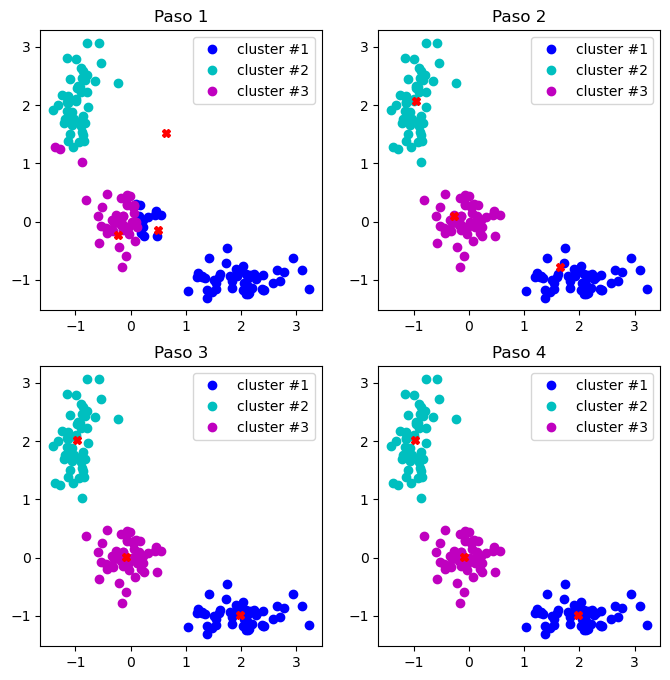

In [2]:
# Scipy has function that takes 2 tuples and return
# calculated distance between them
from scipy.spatial.distance import cdist


# Scipy has function that takes 2 tuples and return
# calculated distance between them
from scipy.spatial.distance import cdist

# Randomly allocate the 3 centroids
np.random.seed(seed=42)
centroids = np.random.normal(loc=0.0, scale=1., size=6)
centroids = centroids.reshape((3, 2))

cent_history = []
cent_history.append(centroids)

for i in range(3):
    # Calculating the distance from a point to a centroid
    distances = cdist(X, centroids)
    # Checking what's the closest centroid for the point
    labels = distances.argmin(axis=1)

    # Labeling the point according the point's distance
    centroids = centroids.copy()
    centroids[0, :] = np.mean(X[labels == 0, :], axis=0)
    centroids[1, :] = np.mean(X[labels == 1, :], axis=0)
    centroids[2, :] = np.mean(X[labels == 2, :], axis=0)

    cent_history.append(centroids)
    
# Let's plot K-means
plt.figure(figsize=(8, 8))
for i in range(4):
    distances = cdist(X, cent_history[i])
    labels = distances.argmin(axis=1)

    plt.subplot(2, 2, i + 1)
    plt.plot(X[labels == 0, 0], X[labels == 0, 1], 'bo', label='cluster #1')
    plt.plot(X[labels == 1, 0], X[labels == 1, 1], 'co', label='cluster #2')
    plt.plot(X[labels == 2, 0], X[labels == 2, 1], 'mo', label='cluster #3')
    plt.plot(cent_history[i][:, 0], cent_history[i][:, 1], 'rX')
    plt.legend(loc=0)
    plt.title('Paso {:}'.format(i + 1))

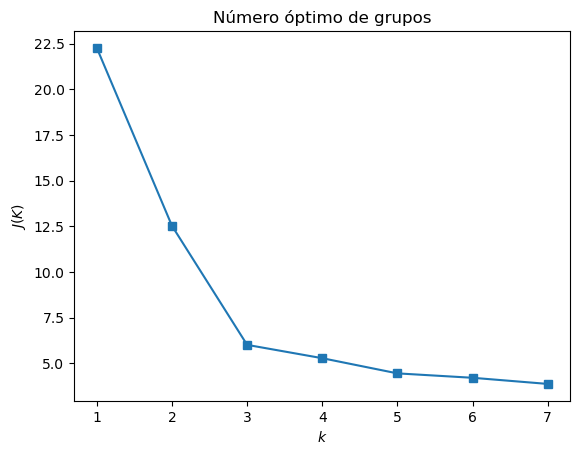

In [4]:
from sklearn.cluster import KMeans

inertia = []
for k in range(1, 8):
    kmeans = KMeans(n_clusters=k, random_state=1).fit(X)
    inertia.append(kmeans.inertia_)
    
plt.plot(range(1, 8), inertia, marker='s')
plt.xlabel('$k$')
plt.ylabel('Inercia $J(K)$')
plt.title('Método del codo');

---

<!-- Section 1 -->
<h2 id="section1" style="color: #007ACC;">Ejemplo 1</h2>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.cluster import KMeans 
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

In [5]:
iris = load_iris()
x = iris['data']

In [6]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', max_iter = 300, n_init = 10, random_state = 0)
    kmeans.fit(x)
    wcss.append(kmeans.inertia_)

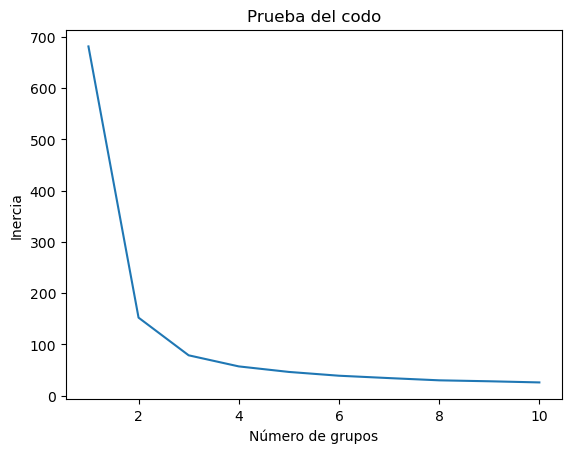

In [7]:
plt.plot(range(1, 11), wcss)
plt.title('Prueba del codo')
plt.xlabel('Número de grupos')
plt.ylabel('Inercia') #within cluster sum of squares
plt.show()

In [8]:
kmeans = KMeans(n_clusters = 3, init = 'k-means++', max_iter = 300, n_init = 10, random_state = 0)
y_kmeans = kmeans.fit_predict(x)

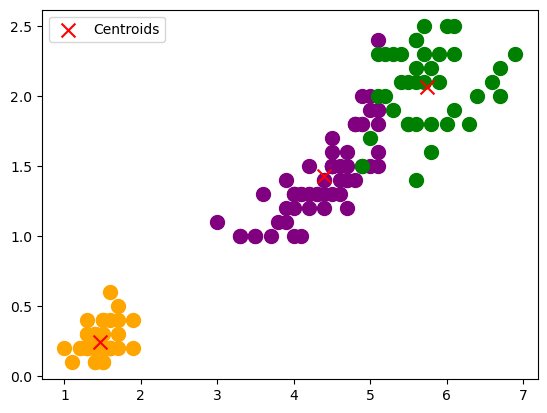

In [9]:
#Visualising the clusters
plt.scatter(x[y_kmeans == 0, 2], x[y_kmeans == 0, 3], s = 100, c = 'purple')
plt.scatter(x[y_kmeans == 1, 2], x[y_kmeans == 1, 3], s = 100, c = 'orange')
plt.scatter(x[y_kmeans == 2, 2], x[y_kmeans == 2, 3], s = 100, c = 'green')

#Plotting the centroids of the clusters
plt.scatter(kmeans.cluster_centers_[:, 2], kmeans.cluster_centers_[:,3], s = 100, marker='x',c = 'red', label = 'Centroids')

plt.legend()

<h2 id="evaluacion" style="color: #007ACC;">Evaluación de los grupos, escalado e inicialización</h2>

A diferencia de la clasificación, en clustering no hay "respuesta correcta" contra la cual comparar, por lo que evaluar un agrupamiento es más delicado. Hay dos tipos de métricas:

- **Internas** (no usan etiquetas): miden qué tan compactos y separados son los grupos. La más usada es el **coeficiente de silueta**, que va de $-1$ a $1$: para cada punto compara la distancia promedio a los puntos de su grupo con la distancia promedio al grupo vecino más cercano. Valores cercanos a $1$ indican grupos compactos y bien separados.
- **Externas** (requieren etiquetas conocidas, algo poco común en la práctica): comparan los grupos con una clasificación de referencia. El **índice de Rand ajustado (ARI)** vale $1$ si la partición coincide exactamente con la de referencia y es cercano a $0$ si equivale a un agrupamiento al azar.

Usamos Iris, donde sí conocemos las especies, para ver qué tanto coinciden ambas métricas:

In [15]:
from sklearn.metrics import adjusted_rand_score

SEED = 42
iris = load_iris()
x, especies = iris['data'], iris['target']

filas = []
for k in range(2, 9):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(x)
    filas.append({'k': k,
                  'silueta': silhouette_score(x, etiquetas),
                  'ARI (vs. especies)': adjusted_rand_score(especies, etiquetas)})
pd.DataFrame(filas).set_index('k').round(3)

,silueta,ARI (vs. especies)
k,,
2,0.681,0.540
3,0.553,0.730
4,0.498,0.650
5,0.491,0.612
6,0.365,0.448
7,0.354,0.481
8,0.349,0.445


La silueta es máxima con $k=2$ (hay una especie, *setosa*, muy separada de las otras dos, que se solapan) mientras que el ARI es máximo con $k=3$, el número real de especies. Esto ilustra que **ninguna métrica interna es una verdad absoluta**: la silueta mide separación geométrica, no si los grupos corresponden a categorías con significado. Conviene combinarla con el método del codo y, sobre todo, con el criterio del problema.

<h3> El escalado importa </h3>

K-Medias usa distancias euclidianas, así que las variables con escalas grandes dominan el agrupamiento. Lo comprobamos con el conjunto `wine` (178 vinos, 13 variables químicas, 3 cultivares), donde la variable `proline` tiene valores del orden de cientos y otras del orden de décimas:

In [16]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

x_vino, cultivar = load_wine(return_X_y=True)

filas = []
for nombre, datos in [('Sin escalar', x_vino), ('Estandarizado', StandardScaler().fit_transform(x_vino))]:
    etiquetas = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(datos)
    filas.append({'datos': nombre,
                  'silueta': silhouette_score(datos, etiquetas),
                  'ARI (vs. cultivar)': adjusted_rand_score(cultivar, etiquetas)})
pd.DataFrame(filas).set_index('datos').round(3)

,silueta,ARI (vs. cultivar)
datos,,
Sin escalar,0.571,0.371
Estandarizado,0.285,0.897


Sin escalar, la silueta es mayor pero el ARI es bajo: los grupos son compactos **solo en el sentido de la variable `proline`**, que domina las distancias, y no reflejan los cultivares. Al estandarizar, la silueta baja pero el agrupamiento recupera mucho mejor los cultivares. Dos lecciones: (1) **estandarice las variables antes de usar K-Medias** cuando están en escalas distintas; (2) **una silueta alta no garantiza un buen agrupamiento**, solo que los grupos son compactos en el espacio donde se calcularon las distancias.

<h3> La inicialización importa </h3>

K-Medias solo garantiza un mínimo *local* de la inercia. Ejecutamos el algoritmo 20 veces con una sola inicialización, usando centroides aleatorios y *k-means++* (que reparte los centroides iniciales lejos unos de otros), y comparamos la inercia final en Iris con $k=3$:

In [17]:
inercias = {
    inicializacion: [KMeans(n_clusters=3, init=inicializacion, n_init=1, random_state=s).fit(x).inertia_
                     for s in range(20)]
    for inicializacion in ('random', 'k-means++')
}
pd.DataFrame({nombre: {'mínima': min(v), 'máxima': max(v)} for nombre, v in inercias.items()}).T.round(2)

,mínima,máxima
random,78.85,145.45
k-means++,78.85,78.86


Con centroides aleatorios, algunas ejecuciones quedan atrapadas en soluciones notablemente peores (inercia mucho mayor); *k-means++* es mucho más estable. Por eso `scikit-learn` usa *k-means++* por defecto y repite el algoritmo `n_init` veces, conservando la mejor solución.

**Ejercicios**

1. Calcule la silueta para $k = 2, \dots, 8$ en el conjunto `wine` ya estandarizado. ¿Qué $k$ sugiere? ¿Coincide con los 3 cultivares?
2. Genere datos con `make_blobs` con grupos de tamaños muy distintos (por ejemplo, 500, 50 y 50 puntos) y aplique K-Medias. ¿Qué ocurre con los grupos pequeños? ¿Qué supuesto del algoritmo se está violando?
3. Aplique K-Medias a `make_moons`. ¿Por qué falla? ¿Qué algoritmo del siguiente cuaderno lo resuelve?

<!-- Section 1 -->
<h2 id="section1" style="color: #007ACC;">Ejemplo 2</h2>

In [10]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

data, labels = load_digits(return_X_y=True)
(n_samples, n_features), n_digits = data.shape, np.unique(labels).size

In [11]:
pd.DataFrame(data)

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,4.0,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0


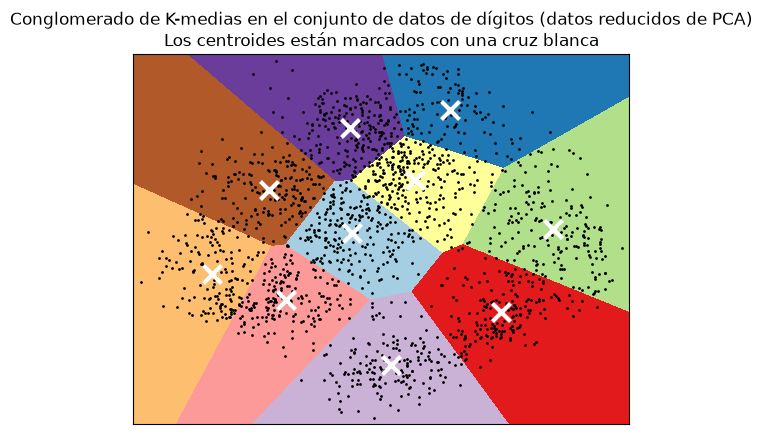

In [12]:
import matplotlib.pyplot as plt

reduced_data = PCA(n_components=2).fit_transform(data)
kmeans = KMeans(init="k-means++", n_clusters=n_digits, n_init=4, random_state=42)
kmeans.fit(reduced_data)

# Step size of the mesh. Decrease to increase the quality of the VQ.
h = 0.02  # point in the mesh [x_min, x_max]x[y_min, y_max].

# Plot the decision boundary. For that, we will assign a color to each
x_min, x_max = reduced_data[:, 0].min() - 1, reduced_data[:, 0].max() + 1
y_min, y_max = reduced_data[:, 1].min() - 1, reduced_data[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Obtain labels for each point in mesh. Use last trained model.
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.figure(1)
plt.clf()
plt.imshow(
    Z,
    interpolation="nearest",
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    cmap=plt.cm.Paired,
    aspect="auto",
    origin="lower",
)

plt.plot(reduced_data[:, 0], reduced_data[:, 1], "k.", markersize=2)
# Plot the centroids as a white X
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="x",
    s=169,
    linewidths=3,
    color="w",
    zorder=10,
)
plt.title(
    "Conglomerado de K-medias en el conjunto de datos de dígitos (datos reducidos de PCA)\n"
    "Los centroides están marcados con una cruz blanca"
)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xticks(())
plt.yticks(())
plt.show()


In [13]:
y = kmeans.predict(reduced_data)

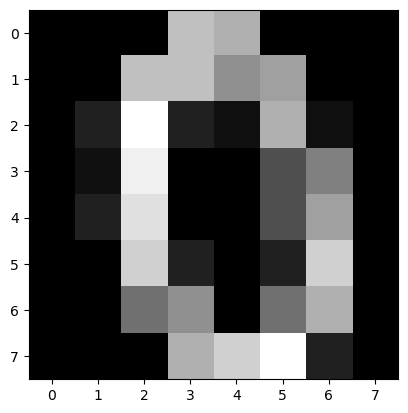

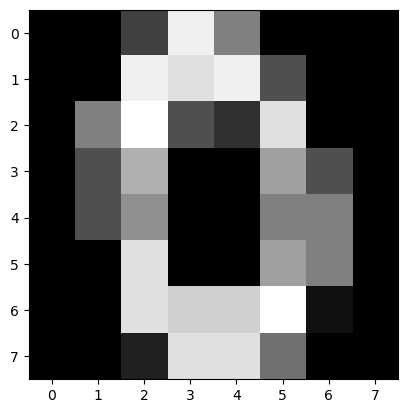

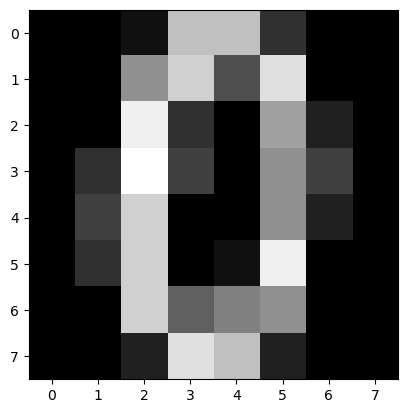

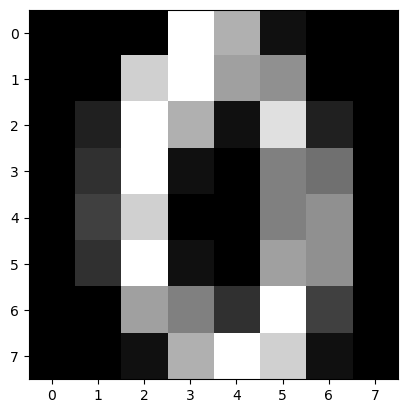

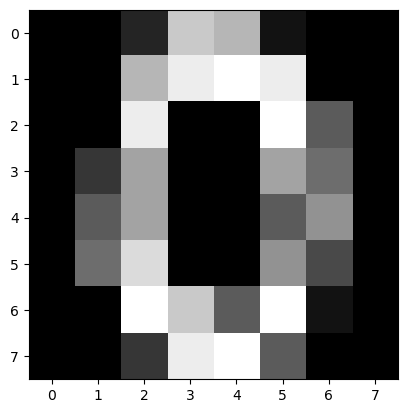

In [14]:
subset_0 = pd.DataFrame(data[y==0]).sample(5)

for data_point in subset_0.iterrows():
    img = data_point[1].to_numpy().reshape(8, 8)
    plt.imshow(img, cmap='gray')
    plt.show()

<!-- References -->
<h2 id="references" style="color: #007ACC;">Referencias</h2>

<ul>
<li>Géron, A. (2022). <i>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow</i> (3.ª ed.), cap. 9: Unsupervised Learning Techniques. O'Reilly.</li>
<li>Arthur, D. y Vassilvitskii, S. (2007). <a href="https://theory.stanford.edu/~sergei/papers/kMeansPP-soda.pdf">k-means++: The advantages of careful seeding</a>. SODA.</li>
<li>Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. <i>Journal of Computational and Applied Mathematics</i>, 20, 53-65.</li>
<li>Documentación de scikit-learn: <a href="https://scikit-learn.org/stable/modules/clustering.html">Clustering</a>.</li>
</ul>